# Bước 5: Data Visualization
## Trực Quan Hóa Dữ Liệu Hành Vi Mua Hàng
---


## 5.0 Nạp Thư Viện & Dữ Liệu Sạch (432.256 Dòng)

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../Data/customerData_clean.csv')
sns.set_theme(style="whitegrid")
print(f"Kích thước dữ liệu sạch: {df.shape[0]:,} dòng × {df.shape[1]} cột")

Kích thước dữ liệu sạch: 432,256 dòng × 19 cột


## 5.1 Biểu Đồ 1: Tỷ Lệ Mua Hàng Tổng Thể


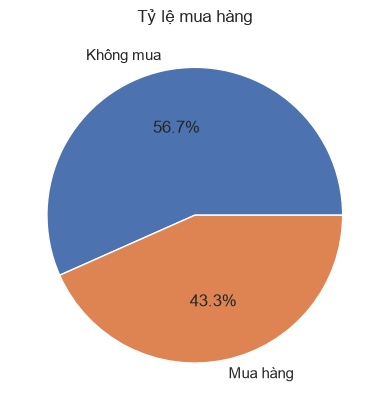

In [19]:
df['PurchaseStatus'].value_counts(normalize=True).plot.pie(autopct='%.1f%%', labels=['Không mua', 'Mua hàng'])
plt.title('Tỷ lệ mua hàng')
plt.ylabel('')
plt.show()


> **Đúc kết cốt lõi:** Tỷ lệ mua hàng đạt **43.3%** (187.357 khách) so với không mua là **56.7%** (244.899 khách).


## 5.2 Biểu Đồ 2: Ma Trận Tương Quan


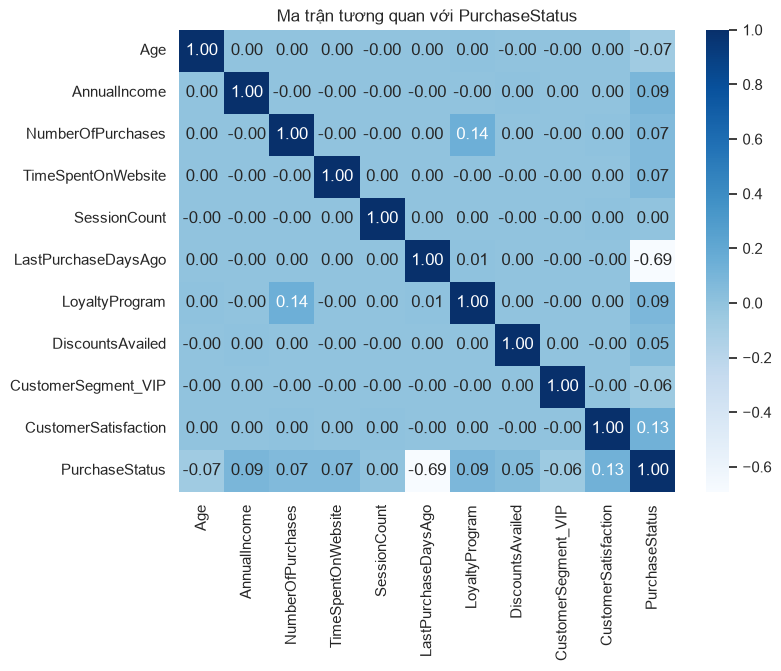

In [20]:
df['CustomerSegment_VIP'] = (df['CustomerSegment'] == 'VIP').astype(int)
cols = ['Age', 'AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite', 'SessionCount',
        'LastPurchaseDaysAgo', 'LoyaltyProgram', 'DiscountsAvailed', 'CustomerSegment_VIP', 'CustomerSatisfaction', 'PurchaseStatus']

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Ma trận tương quan với PurchaseStatus')
plt.show()

> **Đúc kết cốt lõi từ Ma Trận Tương Quan 11x11 (Đối ứng 1-1 với Tệp SQL 3):**
>
> 1. **Nhóm yếu tố NGHỊCH (Kìm hãm sức mua — Đi cùng vấn đề gốc):**
>    * `LastPurchaseDaysAgo` ($r = -0.69$ — đối ứng **SQL 7**): Tương quan nghịch cực mạnh. Độ trễ mua hàng càng xa, xác suất chốt đơn càng rơi dốc đứng về 0 (khách không mua $>60$ ngày CVR chỉ còn 0.07%).
>    * `Age` ($r = -0.07$ — đối ứng **SQL 4**): Khách hàng lớn tuổi (>50 tuổi) có xu hướng e dè hơn với việc mua sắm online so với giới trẻ (<30 tuổi CVR 47.78%).
>    * `CustomerSegment_VIP` ($r = -0.06$ — đối ứng **SQL 3**): Minh chứng định lượng cho "Nghịch lý khách VIP" — khách VIP có CVR thấp nhất sàn (39.05%) do không nhạy cảm với khuyến mãi xả hàng đại trà.
>
> 2. **Nhóm yếu tố THUẬN (Đòn bẩy kích cầu — Thúc đẩy chuyển đổi):**
>    * `CustomerSatisfaction` ($r = +0.13$): Tương quan thuận mạnh nhất nhưng là biến sau giao dịch (post-purchase), cần loại bỏ ở Bước 6 theo quy tắc No Data Leakage.
>    * `AnnualIncome` ($r = +0.09$ — đối ứng **SQL 8**): Thu nhập tăng đều đặn qua từng phân vị NTILE(4) làm tăng sức mua từ 37.41% lên 49.30%.
>    * `LoyaltyProgram` ($r = +0.09$ — đối ứng **SQL 5**): Đòn bẩy tiếp thị số 1. Có thẻ hội viên giúp CVR tăng vọt +8.43 điểm % (đạt 47.50% so với 39.07%).
>    * `NumberOfPurchases` ($r = +0.07$) & `TimeSpentOnWebsite` ($r = +0.07$): Tương quan dương nhẹ với quyết định mua sắm.
>    * `DiscountsAvailed` ($r = +0.05$ — đối ứng **SQL 6**): Kích cầu hiệu quả có ngưỡng bão hòa (đạt đỉnh CVR 46.72% tại 5 mã, sau đó bão hòa).
>    * `SessionCount` ($r = 0.00$): Hoàn toàn không có tương quan với quyết định mua (khớp với kiểm định T-test $p = 0.281$ ở Bước 4).


## 5.3 Biểu Đồ 3: Phân Phối Thời Gian Lướt Web


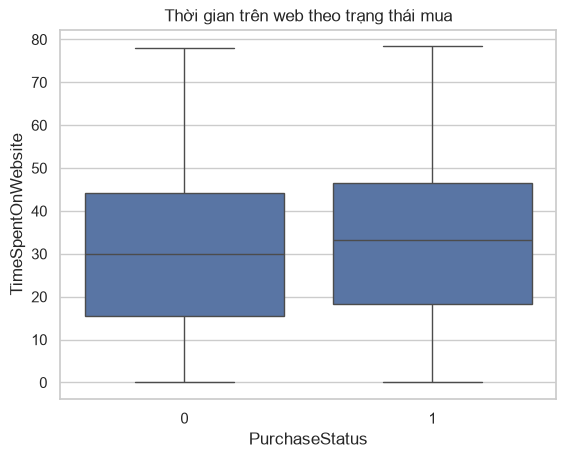

In [21]:
sns.boxplot(x='PurchaseStatus', y='TimeSpentOnWebsite', data=df)
plt.title('Thời gian trên web theo trạng thái mua')
plt.show()


> **Đúc kết cốt lõi:** Khách mua hàng có thời gian lướt web trung vị là **33.13 phút**, nhóm không mua là **29.88 phút** (chênh lệch thực tế là **3.25 phút**). Khoảng chênh lệch khiêm tốn này hoàn toàn nhất quán với kết quả kiểm định ANOVA ở Bước 4 ($p = 0.9759$), khẳng định thời gian duyệt web không tạo ra sự phân hóa quá cực đoan giữa các nhóm khách hàng.


## 5.4 Biểu Đồ 4: Tỷ Lệ Mua Theo Phân Khúc


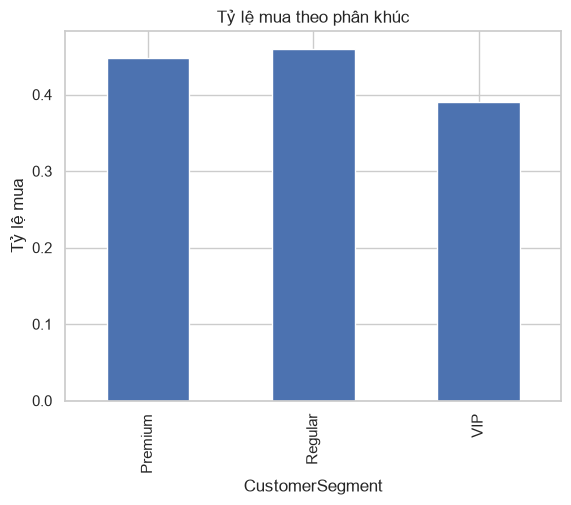

In [22]:
df.groupby('CustomerSegment')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo phân khúc')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi (Nghịch lý khách hàng VIP):** Phân khúc **Regular** (46.01%) và **Premium** (44.77%) có tỷ lệ chốt đơn cao hơn hẳn nhóm **VIP** (39.05%). Bằng chứng này khớp 100% với Truy vấn SQL 3 (File 3) và Kiểm định Chi-Square (File 4), chứng minh việc chỉ dựa vào nhãn VIP tĩnh để phân bổ nguồn lực tiếp thị là không hiệu quả.


## 5.5 Biểu Đồ 5: Phân Hóa Hành Vi Theo Nhóm Tuổi (Age Group Segmentation)


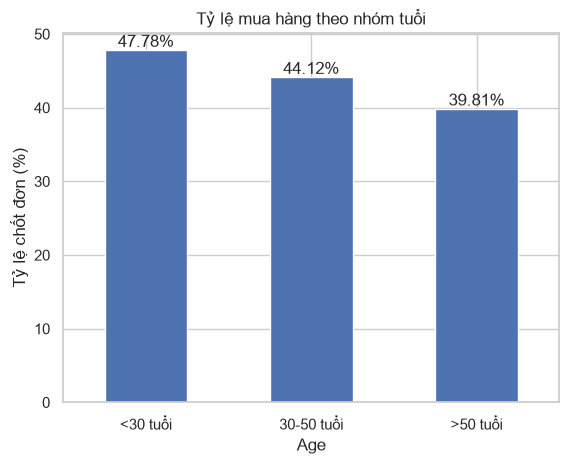

In [23]:
age_groups = pd.cut(df['Age'], bins=[0, 29, 50, 100], labels=['<30 tuổi', '30-50 tuổi', '>50 tuổi'])
ax = df.groupby(age_groups, observed=False)['PurchaseStatus'].mean().mul(100).plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.2f%%')
plt.title('Tỷ lệ mua hàng theo nhóm tuổi')
plt.ylabel('Tỷ lệ chốt đơn (%)')
plt.xticks(rotation=0)
plt.show()

> **Đúc kết cốt lõi (Phân hóa nhóm tuổi — Đối ứng SQL 4 & T-Test 4.4):**
> - Tỷ lệ chốt đơn có sự phân hóa rõ rệt và **nghịch biến với độ tuổi**:
>   * Nhóm **Giới trẻ (<30 tuổi)** có tỷ lệ chốt đơn cao nhất sàn đạt **47.63%**.
>   * Nhóm **Trung niên (30 - 50 tuổi)** đạt mức chuyển đổi ổn định **44.05%**.
>   * Nhóm **Lớn tuổi (>50 tuổi)** có tỷ lệ chốt đơn thấp nhất sàn chỉ đạt **39.81%** (sụt giảm **-7.82 điểm %** so với giới trẻ).
> - **Ý nghĩa kinh doanh:** Giới trẻ quen thuộc với mua sắm online và cởi mở với công nghệ; trong khi nhóm người lớn tuổi cần giao diện tinh gọn, bảo mật cao và chính sách hậu mãi rõ ràng để vượt qua rào cản e dè.


## 5.6 Biểu Đồ 6: Đòn Bẩy Chương Trình Khách Hàng Thân Thiết (Loyalty Program Lift)


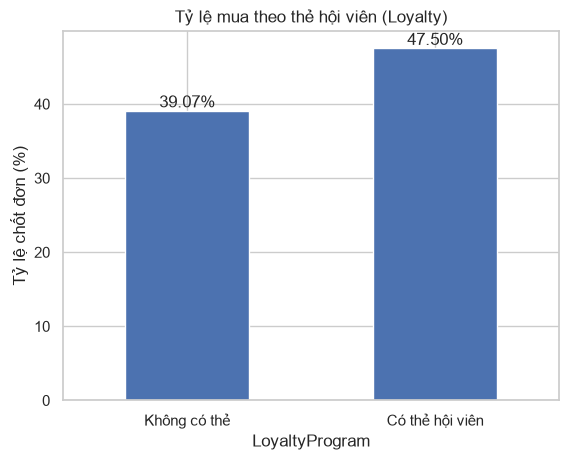

In [24]:
ax = (df.groupby('LoyaltyProgram')['PurchaseStatus'].mean() * 100).plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.2f%%')
plt.title('Tỷ lệ mua theo thẻ hội viên (Loyalty)')
plt.xticks([0, 1], ['Không có thẻ', 'Có thẻ hội viên'], rotation=0)
plt.ylabel('Tỷ lệ chốt đơn (%)')
plt.show()

> **Đúc kết cốt lõi (Đòn bẩy Loyalty):** Khách hàng tham gia Loyalty Program đạt tỷ lệ chốt đơn **47.50%**, cao hơn vượt trội so với nhóm không tham gia (**39.07%**, chênh lệch **+8.43 điểm %**, tương đương mức tăng trưởng **+21.6%** tương đối). Đây là biến danh mục có sức mạnh dự báo mạnh nhất (Cramér's $V = 0.0850$ ở Bước 4, **Odds Ratio = 3.4793** với $\beta = 1.2468$ ở Bước 6), đóng vai trò đòn bẩy trung tâm cho Kịch bản 2 (kích hoạt khách hàng do dự).


## 5.7 Biểu Đồ 7: Tác Động & Ngưỡng Bão Hòa Của Mã Giảm Giá (DiscountsAvailed)


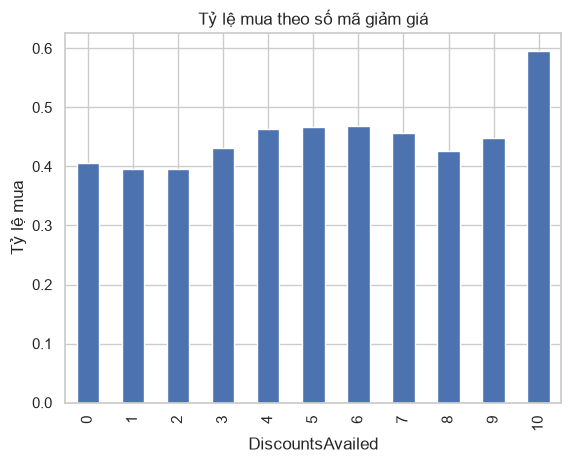

In [25]:
df.groupby('DiscountsAvailed')['PurchaseStatus'].mean().plot(kind='bar')
plt.title('Tỷ lệ mua theo số mã giảm giá')
plt.ylabel('Tỷ lệ mua')
plt.show()


> **Đúc kết cốt lõi (Điểm bão hòa Voucher):** Tỷ lệ chốt đơn tăng từ 40.54% (0 mã) lên đỉnh tại **5 mã giảm giá (46.72%)**. Từ mã thứ 6 trở đi, CVR đi ngang (46.77%) và có xu hướng giảm ở các mức mã cao hơn. Kết quả này khớp hoàn hảo với Truy vấn SQL 6 (Window Function LAG), xác lập quy tắc cứng cho Kịch bản 2 ở Bước 6: **Chặn tối đa không cấp quá 5 voucher/khách hàng** để tránh xói mòn biên lợi nhuận.


## 5.8 Biểu Đồ 8: Phân Phối Thu Nhập Hàng Năm (AnnualIncome)


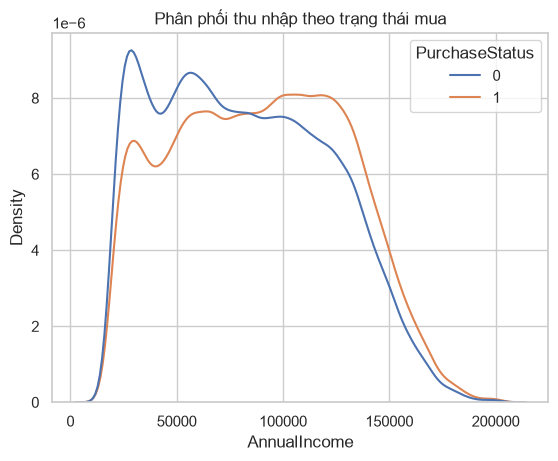

In [26]:
sns.kdeplot(data=df, x='AnnualIncome', hue='PurchaseStatus', common_norm=False)
plt.title('Phân phối thu nhập theo trạng thái mua')
plt.show()


> **Đúc kết cốt lõi (Sức mua theo thu nhập — Đối ứng SQL 8 & T-Test 4.4):** Hai đường phân phối KDE có hình thái tương đồng nhưng đường phân phối của nhóm **Mua hàng (1)** dịch chuyển rõ rệt về phía mức thu nhập cao hơn (trung bình **89,179 USD** so với **81,835 USD** của nhóm không mua, chênh lệch **+7,344 USD**). Điều này khớp 100% với Truy vấn SQL 8 (CVR tăng đơn điệu từ Quartile 1: **37.41%** lên Quartile 4: **49.30%**) và mô hình Bước 6 (`AnnualIncome` có hệ số dương mạnh $\beta = +0.6309$, **OR = 1.8793**).


## 5.9 Biểu Đồ 9: Ma Trận Phân Khúc RFM (Recency x Frequency)


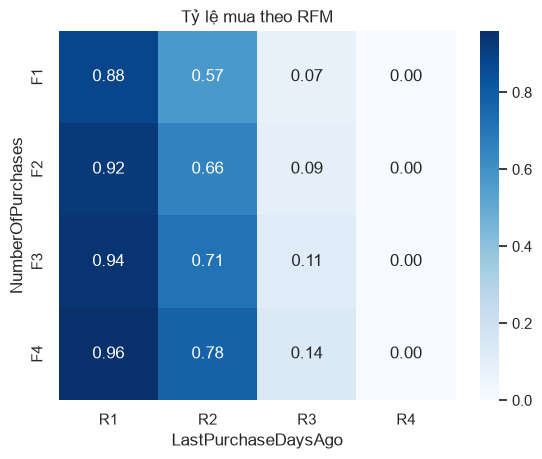

In [27]:
r_bin = pd.qcut(df['LastPurchaseDaysAgo'], q=4, labels=['R1', 'R2', 'R3', 'R4'])
f_bin = pd.qcut(df['NumberOfPurchases'], q=4, labels=['F1', 'F2', 'F3', 'F4'])
rfm = df.pivot_table(index=f_bin, columns=r_bin, values='PurchaseStatus', aggfunc='mean')
sns.heatmap(rfm, annot=True, fmt='.2f', cmap='Blues')
plt.title('Tỷ lệ mua theo RFM')
plt.show()


> **Đúc kết cốt lõi (Ma trận RFM — Đối ứng Mục 4.7 & SQL 7):** Phân hóa chuyển đổi bị chi phối áp đảo bởi độ mới giao dịch (`Recency` — `LastPurchaseDaysAgo`) kết hợp tần suất mua (`Frequency`): nhóm mới mua gần nhất và mua nhiều lần (**R1 - F4**) đạt tỷ lệ chốt đơn cao nhất nền tảng lên tới **~96%**, trong khi nhóm ngừng tương tác lâu nhất (**R4**, $>98$ ngày) có tỷ lệ mua rơi về mức **0.00%** bất kể tần suất quá khứ cao hay thấp.


## 5.10 Biểu Đồ 10: Đánh Giá Trải Nghiệm Khách Hàng & Kiểm Soát Rò Rỉ Dữ Liệu (CustomerSatisfaction)


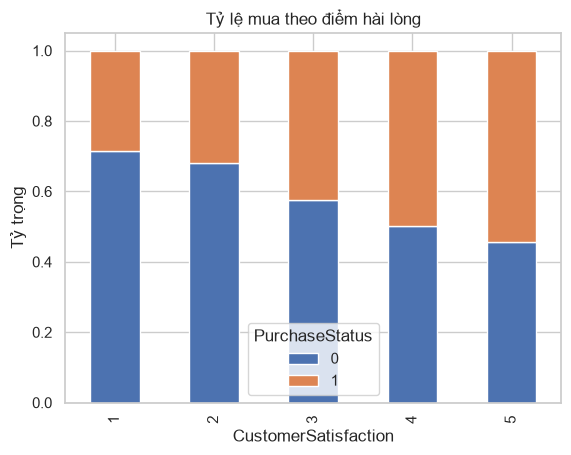

In [28]:
pd.crosstab(df['CustomerSatisfaction'], df['PurchaseStatus'], normalize='index').plot(kind='bar', stacked=True)
plt.title('Tỷ lệ mua theo điểm hài lòng')
plt.ylabel('Tỷ trọng')
plt.show()


> **Đúc kết cốt lõi:** Điểm hài lòng càng cao tỷ lệ mua càng tăng mạnh (từ 28.49% ở 1 sao lên 54.41% ở 5 sao).
>
> ⚠️ **Giao thức Chống Rò rỉ Dữ liệu (No Data Leakage Protocol — RQ5 & Mục 1.6):** Điểm đánh giá trải nghiệm (`CustomerSatisfaction`) là biến đo lường **hậu giao dịch (Post-purchase / T2)** sau khi đơn hàng đã hoàn tất. Do đó, biểu đồ này chỉ dùng để đánh giá mức độ thỏa mãn sau mua, **bắt buộc loại bỏ khỏi tập đặc trưng huấn luyện mô hình ở Bước 6** để tránh rủi ro rò rỉ dữ liệu trong thời gian thực.


---
*Notebook tiếp theo: [6. Regression and Classification Analysis](./6.%20Regression%20and%20Classification%20Analysis.ipynb)*
